<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Carga y exploración del dump de Wikipedia en inglés</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Qué trae el dump, qué se tomó de él y cómo se armó el grafo de enlaces.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Este notebook convierte el dump de la Wikipedia en inglés en un grafo de enlaces entre artículos. Sobre ese grafo, los notebooks 2, 3 y 4 calculan PageRank, HITS, PageRank por tema y recomendaciones.

### El archivo

La Fundación Wikimedia publica copias de Wikipedia. Usamos `enwiki-latest-pages-articles-multistream.xml.bz2`, que trae **la última versión** de cada página de contenido, en XML, con su texto en *wikitexto*.

El archivo pesa 26.9 GB comprimido y 117.8 GB descomprimido. Está dividido en bloques comprimidos de 100 páginas (*streams*), y lo acompaña un índice que dice en qué byte empieza cada bloque. Por eso se puede abrir un artículo sin recorrer el archivo, y varios procesos pueden leerlo a la vez.

### Qué se tomó y qué no

Leímos las 25.9 millones de páginas una por una, pero nunca descomprimimos el archivo a disco ni guardamos el texto.

| Qué pasó | Datos |
|---|---|
| **Entra al grafo** | Identificador, título, enlaces `[[…]]`, categorías, destino de cada redirección, marca de desambiguación |
| **Se guarda, solo para describir** | Fecha y autor de la última edición, tamaño del texto |
| **Se lee y se descarta** | El texto, las plantillas, las veces que se repite un enlace y el lugar donde aparece |
| **No viene en el archivo** | Historial de ediciones, páginas de discusión, visitas, fecha de creación, plantillas ya expandidas |

### Cómo se modeló y qué otras opciones había

| Decisión | Qué hicimos | Otra opción | Por qué esta |
|---|---|---|---|
| **Nodo** | Un artículo | Una categoría o un editor | Queremos medir artículos. Para editores haría falta el historial, que no viene |
| **Arista** | Enlace escrito en el texto | Incluir los enlaces de las plantillas | Expandir plantillas requiere otra fuente de datos |
| **Peso** | Sin peso | Contar repeticiones o clics | No guardamos las repeticiones y el archivo no trae clics |
| **Dirección** | Dirigida | No dirigida | HITS necesita la dirección para separar hubs de autoridades |
| **Redirecciones** | Se cambian por su destino, un salto | Tratarlas como nodos | `[[USA]]` y `[[United States]]` son el mismo artículo |
| **Desambiguaciones** | Se quitan en el análisis | Dejarlas | Son menús, no contenido. El notebook 2 mide que casi no cambia el resultado |
| **Alcance** | Todo el grafo | Una muestra | Una muestra rompería los caminos entre artículos, que es lo que se está midiendo |
| **Temas** | Categorías de Wikipedia | Comunidades del grafo o texto | Las categorías ya tienen nombre, y permiten comprobar los resultados |

### Contenido

1. Entorno.
2. Inspección del archivo.
3. Índice y lectura de un solo artículo.
4. Extracción en paralelo.
5. Carga en Spark.
6. Descripción de los datos.
7. Construcción del grafo.
8. Conclusiones y limitaciones.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · ENTORNO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Entorno</span></div>

Las funciones de lectura están en [`wiki_extract.py`](../wiki_extract.py). Spark necesita Java 17 y, en Windows, los binarios `winutils.exe` y `hadoop.dll` en `HADOOP_HOME`.

In [1]:
import os, sys, glob, json, time, bz2, html
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, "..")   # wiki_extract.py está en la carpeta Wikipedia/
import wiki_extract as we

DATA = Path("..") / "data"
RUTA_XML = DATA / "enwiki-latest-pages-articles-multistream.xml.bz2"
RUTA_IDX = DATA / "enwiki-latest-pages-articles-multistream-index.txt.bz2"
GRAFO = DATA / "grafo"

# Java y Hadoop para PySpark
if "JAVA_HOME" not in os.environ:
    jdks = sorted(glob.glob(r"C:\Program Files\Eclipse Adoptium\jdk-17*"))
    if jdks:
        os.environ["JAVA_HOME"] = jdks[-1]
os.environ.setdefault("HADOOP_HOME", r"C:\hadoop")
os.environ["PATH"] = str(Path(os.environ["HADOOP_HOME"]) / "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.2f}".format)

# Paleta única del repositorio: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#DDDDDD", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

print("JAVA_HOME  :", os.environ.get("JAVA_HOME"))
print("HADOOP_HOME:", os.environ.get("HADOOP_HOME"), "| winutils:", (Path(os.environ["HADOOP_HOME"]) / "bin" / "winutils.exe").exists())

JAVA_HOME  : C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot
HADOOP_HOME: C:\hadoop | winutils: True


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Inspección del archivo</span></div>

Antes de procesarlo, vemos cómo está hecho. Estos son los primeros caracteres del XML:

In [3]:
with bz2.open(RUTA_XML, "rt", encoding="utf-8") as f:
    inicio = f.read(4200)
print(inicio)

<mediawiki xmlns="http://www.mediawiki.org/xml/export-0.11/" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.mediawiki.org/xml/export-0.11/ http://www.mediawiki.org/xml/export-0.11.xsd" version="0.11" xml:lang="en">
  <siteinfo>
    <sitename>Wikipedia</sitename>
    <dbname>enwiki</dbname>
    <base>https://en.wikipedia.org/wiki/Main_Page</base>
    <generator>MediaWiki 1.47.0-wmf.21</generator>
    <case>first-letter</case>
    <namespaces>
      <namespace key="-2" case="first-letter">Media</namespace>
      <namespace key="-1" case="first-letter">Special</namespace>
      <namespace key="0" case="first-letter" />
      <namespace key="1" case="first-letter">Talk</namespace>
      <namespace key="2" case="first-letter">User</namespace>
      <namespace key="3" case="first-letter">User talk</namespace>
      <namespace key="4" case="first-letter">Wikipedia</namespace>
      <namespace key="5" case="first-letter">Wikipedia talk</namespace>
      <n

El primer bloque describe el sitio y sus *namespaces*, los tipos de página de Wikipedia.

In [4]:
with bz2.open(RUTA_IDX, "rt", encoding="utf-8") as f:
    primer_offset = int(f.readline().split(":", 1)[0])

cabecera = we.leer_cabecera(RUTA_XML, primer_offset)
NSX = "{http://www.mediawiki.org/xml/export-0.11/}"
raiz = ET.fromstring(cabecera + "</mediawiki>")
si = raiz.find(f"{NSX}siteinfo")

print("Primer offset (bytes del stream de cabecera):", primer_offset)
print("Versión del esquema de exportación:", raiz.get("version"), "| idioma:", raiz.get(f"{{http://www.w3.org/XML/1998/namespace}}lang"))
for campo in ("sitename", "dbname", "base", "generator", "case"):
    print(f"  {campo:10s}: {si.findtext(NSX + campo)}")

namespaces = pd.DataFrame(
    [(int(n.get("key")), n.text or "(artículos)", n.get("case")) for n in si.find(f"{NSX}namespaces")],
    columns=["ns", "nombre", "case"],
)
NS_NOMBRE = dict(zip(namespaces.ns, namespaces.nombre))
namespaces

Primer offset (bytes del stream de cabecera): 570
Versión del esquema de exportación: 0.11 | idioma: en
  sitename  : Wikipedia
  dbname    : enwiki
  base      : https://en.wikipedia.org/wiki/Main_Page
  generator : MediaWiki 1.47.0-wmf.21
  case      : first-letter


,ns,nombre,case
0,-2,Media,first-letter
1,-1,Special,first-letter
2,0,(artículos),first-letter
3,1,Talk,first-letter
4,2,User,first-letter
5,3,User talk,first-letter
6,4,Wikipedia,first-letter
7,5,Wikipedia talk,first-letter
8,6,File,first-letter
9,7,File talk,first-letter


Los artículos están en **ns = 0**, que no tiene prefijo. Los demás tipos llevan uno en el título, como `Category:`, `Template:` o `File:`. Más adelante vemos que el archivo solo trae namespaces pares: las páginas de discusión, que son los impares, no vienen.

Cada página trae una sola revisión. Por ejemplo, la primera página del archivo es una redirección:

In [5]:
print(we.leer_articulo(RUTA_XML, primer_offset, "AccessibleComputing"))

<page>
    <title>AccessibleComputing</title>
    <ns>0</ns>
    <id>10</id>
    <redirect title="Computer accessibility" />
    <revision>
      <id>1367012995</id>
      <parentid>1362980932</parentid>
      <timestamp>2026-07-31T12:02:55Z</timestamp>
      <contributor>
        <username>Graham87</username>
        <id>194203</id>
      </contributor>
      <minor />
      <comment>1 revision imported: import old edit from [[nost:AccessibleComputing]]</comment>
      <origin>1362980932</origin>
      <model>wikitext</model>
      <format>text/x-wiki</format>
      <text bytes="111" sha1="kmysdltgexdwkv2xsml3j44jb56dxvn" xml:space="preserve">#REDIRECT [[Computer accessibility]]

{{rcat shell|
{{R from move}}
{{R from CamelCase}}
{{R unprintworthy}}
}}</text>
      <sha1>kmysdltgexdwkv2xsml3j44jb56dxvn</sha1>
    </revision>
</page>


Del texto de cada página nos interesan dos cosas:

- `[[Destino]]` o `[[Destino|texto visible]]`: un **enlace** a otro artículo. Con ellos se forman las aristas.
- `[[Category:Nombre]]`: la página pertenece a esa **categoría**.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Índice y lectura de un solo artículo</span></div>

Cada línea del índice tiene el formato `byte:page_id:título`. Las 100 páginas de un bloque comparten el mismo byte de inicio.

In [6]:
with bz2.open(RUTA_IDX, "rt", encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

t0 = time.time()
DEMO = ["PageRank", "Mexico", "Anarchism", "National Autonomous University of Mexico"]
offsets, n_paginas_idx, encontrados = we.leer_indice(RUTA_IDX, DEMO)
print(f"\nÍndice leído en {time.time() - t0:.0f} s")
print(f"Páginas en el índice : {n_paginas_idx:,}")
print(f"Streams bz2          : {len(offsets):,}   (≈ {n_paginas_idx / len(offsets):.1f} páginas por stream)")
print(f"Último offset        : {offsets[-1]:,} de {RUTA_XML.stat().st_size:,} bytes")

570:10:AccessibleComputing
570:12:Anarchism
570:13:AfghanistanHistory
570:14:AfghanistanGeography
570:15:AfghanistanPeople



Índice leído en 49 s
Páginas en el índice : 25,932,219
Streams bz2          : 259,358   (≈ 100.0 páginas por stream)
Último offset        : 26,917,192,226 de 26,917,225,724 bytes


El archivo está ordenado por `page_id`, que se asigna al crear la página. Un `page_id` bajo sugiere una página antigua, pero solo es una aproximación, porque el archivo no trae la fecha de creación.

Con el índice podemos abrir cualquier artículo descomprimiendo un solo bloque:

In [8]:
for titulo, (off, pid) in encontrados.items():
    t0 = time.time()
    xml_pag = we.leer_articulo(RUTA_XML, off, titulo)
    print(f"{titulo!r:45s} page_id={pid:<9} offset={off:>14,}  -> {len(xml_pag):>9,} caracteres en {1000 * (time.time() - t0):.0f} ms")

print("\n" + we.leer_articulo(RUTA_XML, *encontrados["PageRank"][:1], "PageRank")[:2500])

'Anarchism'                                   page_id=12        offset=           570  ->   115,493 caracteres en 93 ms
'National Autonomous University of Mexico'    page_id=145426    offset=   682,063,690  ->   104,400 caracteres en 100 ms
'Mexico'                                      page_id=3966054   offset= 4,464,216,278  ->   271,419 caracteres en 23 ms
'PageRank'                                    page_id=26334893  offset=11,268,858,975  ->    77,930 caracteres en 11 ms

<page>
    <title>PageRank</title>
    <ns>0</ns>
    <id>26334893</id>
    <revision>
      <id>1378661007</id>
      <parentid>1378042705</parentid>
      <timestamp>2026-10-05T14:42:16Z</timestamp>
      <contributor>
        <username>Mindmatrix</username>
        <id>160367</id>
      </contributor>
      <minor />
      <comment>revert - see [[WP:SDFORMAT]]</comment>
      <origin>1378661007</origin>
      <model>wikitext</model>
      <format>text/x-wiki</format>
      <text bytes="74353" sha1="9uc14m1i1sx

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXTRACCIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Extracción en paralelo</span></div>

Repartimos los bloques en 400 rangos y los procesan 14 procesos. Cada proceso:

1. Lee su rango y descomprime bloque por bloque, en memoria.
2. Lee cada página del XML.
3. Saca los enlaces y las categorías del texto, y normaliza los títulos como lo hace Wikipedia: `_` se vuelve espacio, la primera letra va en mayúscula y se quita `#sección`. Los enlaces a otros namespaces o a otros idiomas se descartan.
4. Escribe tres tablas en Parquet y descarta el texto.

| Tabla | Filas | Columnas principales |
|---|---|---|
| `paginas` | Todas las páginas | `page_id`, `title`, `ns`, `is_redirect`, `redirect_target`, `timestamp`, `contributor_user`, `text_bytes`, `is_disambig` |
| `enlaces` | Un enlace distinto por artículo | `src_id`, `dst_title` |
| `categorias` | Una fila por categoría de cada página | `page_id`, `category` |

Si se interrumpe, los rangos ya escritos no se vuelven a procesar.

In [9]:
t0 = time.time()
stats = pd.DataFrame(we.extraer_todo(RUTA_XML, offsets, DATA, procesos=14, n_tareas=400))
print(f"Llamada terminada en {time.time() - t0:,.0f} s ({stats.omitido.sum()} de {len(stats)} rangos ya estaban procesados)")

# Tiempo real de la extracción, calculado a partir de las marcas de tiempo de cada tarea
inicio_real = (stats.fin_unix - stats.segundos).min()
duracion = stats.fin_unix.max() - inicio_real
resumen = pd.Series({
    "rangos procesados": len(stats),
    "streams": stats.streams.sum(),
    "páginas": stats.paginas.sum(),
    "enlaces (artículo → título)": stats.enlaces.sum(),
    "pertenencias a categoría": stats.categorias.sum(),
    "GB comprimidos leídos": stats.bytes_comp.sum() / 1e9,
    "GB de XML descomprimido": stats.bytes_xml.sum() / 1e9,
    "duración real (min)": duracion / 60,
    "throughput (MB/s comprimidos)": stats.bytes_comp.sum() / 1e6 / duracion,
    "throughput (MB/s XML)": stats.bytes_xml.sum() / 1e6 / duracion,
})
print(resumen.to_string(float_format="{:,.1f}".format))

extra = stats.streams.sum() - len(offsets)
print(f"\nStreams leídos: {stats.streams.sum():,} = {len(offsets):,} del índice + {extra} sin páginas")
assert stats.paginas.sum() == n_paginas_idx, "El número de páginas no coincide con el índice"

# Orden del archivo: page_id estrictamente creciente en todas las partes, en orden de bytes
ids_archivo = np.concatenate([pd.read_parquet(p, columns=["page_id"]).page_id.to_numpy()
                              for p in sorted((DATA / "paginas").glob("part-*.parquet"))])
assert np.all(np.diff(ids_archivo) > 0)
print(f"✔ page_id estrictamente creciente a lo largo del archivo: de {ids_archivo[0]:,} a {ids_archivo[-1]:,}")
print("✔ Verificación: se extrajeron exactamente las", f"{n_paginas_idx:,}", "páginas del índice")

Llamada terminada en 1,583 s (0 de 400 rangos ya estaban procesados)
rangos procesados                       400.0
streams                             259,360.0
páginas                          25,932,219.0
enlaces (artículo → título)     254,346,209.0
pertenencias a categoría         47,705,914.0
GB comprimidos leídos                    26.9
GB de XML descomprimido                 117.8
duración real (min)                      26.4
throughput (MB/s comprimidos)            17.0
throughput (MB/s XML)                    74.5

Streams leídos: 259,360 = 259,358 del índice + 2 sin páginas


✔ page_id estrictamente creciente a lo largo del archivo: de 10 a 84,442,244
✔ Verificación: se extrajeron exactamente las 25,932,219 páginas del índice


Se leen 2 bloques más de los que lista el índice porque hay dos sin páginas: uno vacío y el que cierra el archivo. El número de páginas coincide exactamente con el índice.

In [10]:
def tam_dir(p):
    return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 1e9

pd.Series({sub: tam_dir(DATA / sub) for sub in ("paginas", "enlaces", "categorias")}, name="GB en disco").to_frame()

,GB en disco
paginas,1.21
enlaces,2.55
categorias,0.49


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · SPARK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Carga en Spark</span></div>

Usamos Spark para agregar y unir tablas tan grandes. Corre en esta misma computadora con todos sus núcleos.

In [11]:
from pyspark.sql import SparkSession, functions as F, Window

spark = (
    SparkSession.builder
    .appName("Practica3-Wikipedia")
    .master("local[*]")
    .config("spark.driver.memory", "20g")
    .config("spark.driver.maxResultSize", "4g")
    .config("spark.sql.shuffle.partitions", "400")
    .config("spark.local.dir", str(Path("..").resolve() / "spark_tmp"))
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| núcleos:", spark.sparkContext.defaultParallelism)

Spark 4.1.2 | núcleos: 16


In [12]:
paginas = spark.read.parquet(str(DATA / "paginas"))
enlaces = spark.read.parquet(str(DATA / "enlaces"))
categorias = spark.read.parquet(str(DATA / "categorias"))
for nombre, df in (("paginas", paginas), ("enlaces", enlaces), ("categorias", categorias)):
    df.createOrReplaceTempView(nombre)

paginas.printSchema()
enlaces.printSchema()
categorias.printSchema()

root
 |-- page_id: long (nullable = true)
 |-- title: string (nullable = true)
 |-- ns: integer (nullable = true)
 |-- is_redirect: boolean (nullable = true)
 |-- redirect_target: string (nullable = true)
 |-- rev_id: long (nullable = true)
 |-- parent_id: long (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- contributor_user: string (nullable = true)
 |-- contributor_id: long (nullable = true)
 |-- contributor_ip: string (nullable = true)
 |-- minor: boolean (nullable = true)
 |-- model: string (nullable = true)
 |-- format: string (nullable = true)
 |-- text_bytes: long (nullable = true)
 |-- n_enlaces: integer (nullable = true)
 |-- n_categorias: integer (nullable = true)
 |-- is_disambig: boolean (nullable = true)

root
 |-- src_id: long (nullable = true)
 |-- dst_title: string (nullable = true)

root
 |-- page_id: long (nullable = true)
 |-- category: string (nullable = true)



In [13]:
conteos = {n: spark.table(n).count() for n in ("paginas", "enlaces", "categorias")}
pd.Series(conteos, name="filas").map("{:,}".format).to_frame()

,filas
paginas,"25,932,219"
enlaces,"254,346,209"
categorias,"47,705,914"


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXPLORACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Descripción de los datos</span></div>

### 6.1 Páginas por tipo

In [15]:
por_ns = spark.sql('''
    SELECT ns, COUNT(*) AS paginas, SUM(CAST(is_redirect AS INT)) AS redirecciones,
           SUM(text_bytes) / 1e9 AS gb_texto
    FROM paginas GROUP BY ns ORDER BY paginas DESC
''').toPandas()
por_ns.insert(1, "nombre", por_ns.ns.map(NS_NOMBRE))
por_ns["% redirección"] = 100 * por_ns.redirecciones / por_ns.paginas
por_ns["% del total"] = 100 * por_ns.paginas / por_ns.paginas.sum()
por_ns

,ns,nombre,paginas,redirecciones,gb_texto,% redirección,% del total
0,0,(artículos),19314502,12065403,71.43,62.47,74.48
1,14,Category,2648210,37,0.43,0.00,10.21
2,4,Wikipedia,1572638,168316,20.79,10.70,6.06
3,6,File,1022983,20295,0.68,1.98,3.94
4,10,Template,903764,190188,1.52,21.04,3.49
5,118,Draft,334269,273382,0.45,81.79,1.29
6,100,Portal,105171,11037,0.16,10.49,0.41
7,828,Module,19626,1926,0.09,9.81,0.08
8,12,Help,2907,1874,0.01,64.47,0.01
9,8,MediaWiki,2810,42,0.01,1.49,0.01


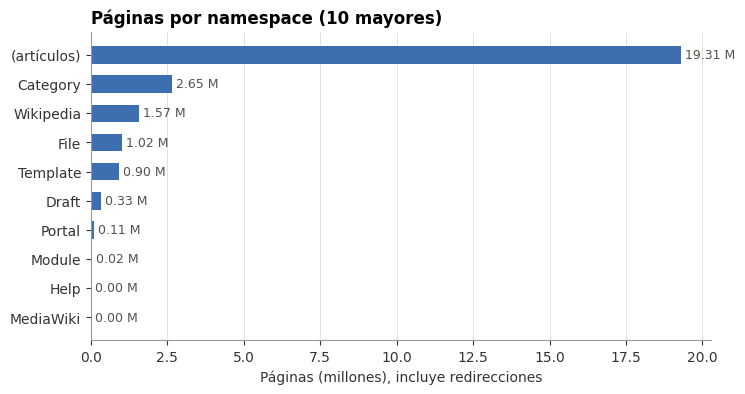

In [16]:
top = por_ns.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.nombre, top.paginas / 1e6, color=AZUL, height=0.6)
for y, v in enumerate(top.paginas / 1e6):
    ax.text(v, y, f" {v:,.2f} M", va="center", color="#52514e", fontsize=9)
ax.set_xlabel("Páginas (millones), incluye redirecciones")
ax.set_title("Páginas por namespace (10 mayores)", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

**Observaciones.** El espacio de artículos concentra el 74.5 % de las páginas, con 19.3 millones. Le siguen las categorías (2.65 millones), las páginas `Wikipedia:` (1.57 millones), los archivos (1.02 millones) y las plantillas (0.90 millones). Solo aparecen namespaces pares, lo que confirma que el archivo no trae páginas de discusión.

In [17]:
art = paginas.filter("ns = 0")
n0 = art.groupBy("is_redirect").count().toPandas().set_index("is_redirect")["count"]
n_desamb = art.filter("is_disambig").count()
print(f"Namespace 0: {n0.sum():,} páginas")
print(f"  artículos (no redirección): {n0[False]:,}  ({100 * n0[False] / n0.sum():.1f} %)")
print(f"  redirecciones             : {n0[True]:,}  ({100 * n0[True] / n0.sum():.1f} %)")
print(f"  de los artículos, páginas de desambiguación / set index: {n_desamb:,}")

Namespace 0: 19,314,502 páginas
  artículos (no redirección): 7,249,099  (37.5 %)
  redirecciones             : 12,065,403  (62.5 %)
  de los artículos, páginas de desambiguación / set index: 372,263


**Sobre la cifra de desambiguaciones.** El 372,263 de esta salida es de una versión anterior de la marca `is_disambig`, que confundía algunas plantillas. Se corrigió en `wiki_extract.py` y se recalculó leyendo otra vez el archivo. La cifra correcta es **369,725**, que es la que usan los notebooks 2, 3 y 4.

### 6.2 Tamaño de los artículos

Percentiles de text_bytes (p10, p25, p50, p75, p90, p99): ['1,138', '2,394', '4,890', '9,945', '20,627', '84,382']


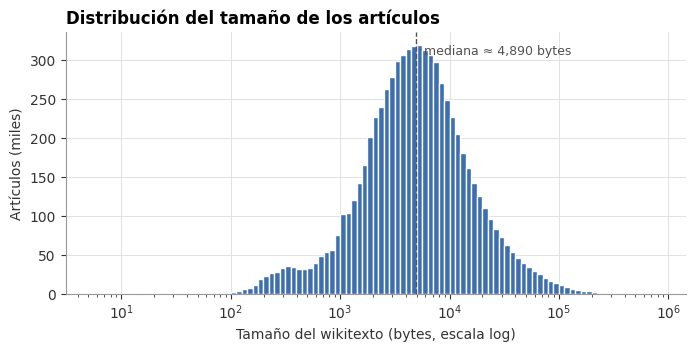

In [18]:
art_txt = paginas.filter("ns = 0 AND NOT is_redirect")
q = art_txt.select(F.percentile_approx("text_bytes", [0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).alias("q")).first().q
print("Percentiles de text_bytes (p10, p25, p50, p75, p90, p99):", [f"{v:,}" for v in q])

hist = (art_txt.filter("text_bytes > 0")
        .select(F.floor(F.log10("text_bytes") * 20).alias("b"))
        .groupBy("b").count().orderBy("b").toPandas())
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(10 ** (hist.b / 20), hist["count"] / 1e3, width=10 ** ((hist.b + 1) / 20) - 10 ** (hist.b / 20),
       align="edge", color=AZUL, edgecolor="#fcfcfb", linewidth=1)
ax.set_xscale("log")
ax.axvline(q[2], color="#52514e", linestyle="--", linewidth=1)
ax.text(q[2], ax.get_ylim()[1] * 0.95, f"  mediana ≈ {q[2]:,} bytes", color="#52514e", va="top", fontsize=9)
ax.set_xlabel("Tamaño del wikitexto (bytes, escala log)")
ax.set_ylabel("Artículos (miles)")
ax.set_title("Distribución del tamaño de los artículos", loc="left")
plt.show()

**Observaciones.** Un artículo típico es corto: la mediana es de 4,890 bytes, y el 10 % tiene menos de 1,138. Hay pocos muy largos: solo el 1 % pasa de 84,382 bytes. El más largo, *Japanese conjugation (mizenkei base)*, llega a 792,627 bytes.

In [19]:
art_txt.orderBy(F.desc("text_bytes")).select("title", "text_bytes", "n_enlaces", "n_categorias").show(10, truncate=60)

+------------------------------------------------------------+----------+---------+------------+
|                                                       title|text_bytes|n_enlaces|n_categorias|
+------------------------------------------------------------+----------+---------+------------+
|                        Japanese conjugation (mizenkei base)|    792627|      233|           2|
|         List of government schools in New South Wales (A–B)|    746752|      347|           1|
|        List of The Adventures of Ozzie and Harriet episodes|    720347|      405|           1|
|                                        Japanese conjugation|    694054|      249|           2|
|                                             List of rodents|    682025|     3367|           3|
|                                         List of 2026 albums|    676424|     3281|           3|
|2024 United States House of Representatives elections in ...|    672290|      630|           3|
|                             

### 6.3 Quién editó al último

In [23]:
# Cuentas que hicieron la última edición de más artículos (suelen ser bots de mantenimiento)
spark.sql('''
    SELECT contributor_user, COUNT(*) AS articulos FROM paginas
    WHERE ns = 0 AND NOT is_redirect AND contributor_user IS NOT NULL
    GROUP BY contributor_user ORDER BY articulos DESC LIMIT 15
''').toPandas()

,contributor_user,articulos
0,ZackBot,553643
1,Zackmann08,335853
2,Jevansen,191387
3,JJMC89 bot III,189768
4,PrimeBOT,178247
5,Staryu,170265
6,GreenC bot,157760
7,Ser Amantio di Nicolao,136716
8,PhuzBot,122609
9,InternetArchiveBot,116656


Esta tabla cuenta quién hizo la última edición de cada artículo, no quién lo escribió. Varias de estas cuentas son bots de mantenimiento. *ZackBot* es el último editor de 553,643 artículos.

### 6.4 Enlaces y categorías por artículo

In [24]:
art_txt.select(
    F.mean("n_enlaces").alias("enlaces_medio"),
    F.percentile_approx("n_enlaces", 0.5).alias("enlaces_mediana"),
    F.max("n_enlaces").alias("enlaces_max"),
    F.mean("n_categorias").alias("categorias_medio"),
    F.sum(F.when(F.col("n_enlaces") == 0, 1).otherwise(0)).alias("sin_enlaces"),
    F.sum(F.when(F.col("n_categorias") == 0, 1).otherwise(0)).alias("sin_categorias"),
).toPandas()

,enlaces_medio,enlaces_mediana,enlaces_max,categorias_medio,sin_enlaces,sin_categorias
0,35.09,18,11987,5.87,7214,431155


In [25]:
# Categorías con más artículos (excluye categorías de mantenimiento, que suelen añadirse por plantillas)
cat_art = categorias.join(art_txt.select("page_id"), "page_id")
cat_art.groupBy("category").count().orderBy(F.desc("count")).show(20, truncate=70)

+--------------------------------------+-------+
|                              category|  count|
+--------------------------------------+-------+
|                         Living people|1149965|
| Year of birth missing (living people)| 173779|
|Place of birth missing (living people)|  66607|
|Men's association football midfielders|  65854|
|   Men's association football forwards|  49980|
|       20th-century American sportsmen|  47899|
|  Men's association football defenders|  46649|
|   Taxonomy articles created by Polbot|  31894|
|       English Football League players|  31142|
|                 Year of birth unknown|  26048|
|             English men's footballers|  24906|
|       21st-century American sportsmen|  24140|
|        American black-and-white films|  23447|
|           Articles created by Qbugbot|  20877|
|                 Year of birth missing|  20041|
|                 Year of death missing|  19964|
|                           1988 births|  18901|
|                   

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · GRAFO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. Construcción del grafo</span></div>

**Nodos:** los artículos, es decir, las páginas con `ns = 0` que no son redirecciones.

**Aristas:** hay una arista $u \to v$ si el texto de $u$ tiene un enlace a $v$. Para armarlas:

- Si el enlace apunta a una redirección, como `[[USA]]`, se cambia por el artículo destino, *United States*.
- Se quitan los enlaces duplicados y los de un artículo a sí mismo.
- Se descartan los enlaces a páginas que no existen.

In [26]:
nodos_base = paginas.filter("ns = 0 AND NOT is_redirect").select(
    F.col("page_id").alias("id"), "title", "is_disambig")

# Redirecciones de ns 0 -> artículo destino (un salto)
redirs = paginas.filter("ns = 0 AND is_redirect").select(
    F.col("title").alias("r_title"), F.col("redirect_target").alias("target"))
redirs_ok = redirs.join(nodos_base.select(F.col("title").alias("target"), "id"), "target")
n_redirs, n_redirs_ok = redirs.count(), redirs_ok.count()
print(f"Redirecciones resueltas a un artículo: {n_redirs_ok:,} de {n_redirs:,} ({100 * n_redirs_ok / n_redirs:.1f} %)")

# Tabla título -> id de artículo (títulos de artículos + títulos de redirecciones)
titulo_a_id = nodos_base.select("title", "id").unionByName(
    redirs_ok.select(F.col("r_title").alias("title"), "id"))

aristas = (enlaces.join(titulo_a_id, enlaces.dst_title == titulo_a_id.title)
           .select(F.col("src_id").alias("src"), F.col("id").alias("dst"))
           .filter("src <> dst")
           .distinct())

t0 = time.time()
aristas.write.mode("overwrite").parquet(str(GRAFO / "aristas"))
print(f"Aristas escritas en {time.time() - t0:,.0f} s")

Redirecciones resueltas a un artículo: 12,037,636 de 12,065,403 (99.8 %)


Aristas escritas en 105 s


Casi todas las redirecciones que no se resuelven apuntan fuera de los artículos, como `Wikify` → `Wikipedia:Glossary`. Además, *200th Division* tiene dos `page_id`, y los enlaces a ese título cuentan para los dos nodos.

In [27]:
aristas = spark.read.parquet(str(GRAFO / "aristas"))   # se relee para cortar el linaje

# Redirecciones que no llegan a un artículo, por motivo
titulos_art = nodos_base.select(F.col("title").alias("target"))
no_resueltas = redirs.join(titulos_art, "target", "left_anti")
motivo = (no_resueltas
          .join(redirs.select(F.col("r_title").alias("target")).distinct().withColumn("es_redir", F.lit(True)), "target", "left")
          .select(F.when(F.col("es_redir"), "doble redirección (el destino es otra redirección)")
                   .when(F.col("target").rlike(r"^(Wikipedia|Category|Template|Portal|Help|Draft|File|MOS|Module|User|Special|Talk|MediaWiki|TimedText|Event)( talk)?:"),
                         "destino en otro namespace")
                   .otherwise("destino inexistente").alias("motivo")))
display(motivo.groupBy("motivo").count().orderBy(F.desc("count")).toPandas())

# Títulos de artículo repetidos (dos page_id con el mismo título)
display(nodos_base.groupBy("title").agg(F.collect_list("id").alias("ids"), F.count("*").alias("n"))
        .filter("n > 1").toPandas())

g_sal = aristas.groupBy(F.col("src").alias("id")).agg(F.count("*").alias("grado_salida"))
g_ent = aristas.groupBy(F.col("dst").alias("id")).agg(F.count("*").alias("grado_entrada"))

nodos_sin_idx = (nodos_base.join(g_sal, "id", "left").join(g_ent, "id", "left")
                 .fillna(0, ["grado_salida", "grado_entrada"]))
idx = nodos_sin_idx.select("id").rdd.map(lambda r: r[0]).sortBy(lambda x: x).zipWithIndex().toDF(["id", "idx"])
nodos = nodos_sin_idx.join(idx, "id").select("id", "idx", "title", "is_disambig", "grado_salida", "grado_entrada")
nodos.write.mode("overwrite").parquet(str(GRAFO / "nodos"))
nodos = spark.read.parquet(str(GRAFO / "nodos"))
nodos.printSchema()

,motivo,count
0,destino en otro namespace,27564
1,doble redirección (el destino es otra redirección),155
2,destino inexistente,50


,title,ids,n
0,200th Division,"[84438847, 3402359]",2


root
 |-- id: long (nullable = true)
 |-- idx: long (nullable = true)
 |-- title: string (nullable = true)
 |-- is_disambig: boolean (nullable = true)
 |-- grado_salida: long (nullable = true)
 |-- grado_entrada: long (nullable = true)



Para definir temas guardamos dos tablas más:

- `categorias_nodo`: a qué categorías pertenece cada artículo.
- `jerarquia_categorias`: qué categorías contienen a otras.

In [28]:
categorias_nodo = categorias.join(nodos.select(F.col("id").alias("page_id")), "page_id") \
                            .select(F.col("page_id").alias("id"), "category")
categorias_nodo.write.mode("overwrite").parquet(str(GRAFO / "categorias_nodo"))

jerarquia = (categorias.join(paginas.filter("ns = 14").select("page_id", "title"), "page_id")
             .select(F.regexp_replace("title", "^Category:", "").alias("categoria"), F.col("category").alias("padre")))
jerarquia.write.mode("overwrite").parquet(str(GRAFO / "jerarquia_categorias"))

categorias_nodo = spark.read.parquet(str(GRAFO / "categorias_nodo"))
jerarquia = spark.read.parquet(str(GRAFO / "jerarquia_categorias"))
print(f"categorias_nodo: {categorias_nodo.count():,} filas | jerarquia_categorias: {jerarquia.count():,} filas")

categorias_nodo: 42,521,214 filas | jerarquia_categorias: 5,184,700 filas


### 7.1 Estadísticas del grafo

In [29]:
r = nodos.agg(
    F.count("*").alias("N"),
    F.sum("grado_salida").alias("E"),
    F.sum(F.when(F.col("grado_salida") == 0, 1).otherwise(0)).alias("dangling"),
    F.sum(F.when(F.col("grado_entrada") == 0, 1).otherwise(0)).alias("sin_entrada"),
    F.sum(F.when((F.col("grado_entrada") == 0) & (F.col("grado_salida") == 0), 1).otherwise(0)).alias("aislados"),
    F.max("grado_salida").alias("max_salida"),
    F.max("grado_entrada").alias("max_entrada"),
).first()
N, E = r.N, r.E
pd.Series({
    "nodos (artículos) N": f"{N:,}",
    "aristas E": f"{E:,}",
    "grado medio E/N": f"{E / N:.2f}",
    "densidad E/(N(N-1))": f"{E / (N * (N - 1)):.2e}",
    "nodos colgantes (sin salida)": f"{r.dangling:,} ({100 * r.dangling / N:.2f} %)",
    "nodos sin enlaces de entrada": f"{r.sin_entrada:,} ({100 * r.sin_entrada / N:.2f} %)",
    "nodos aislados": f"{r.aislados:,}",
    "grado de salida máximo": f"{r.max_salida:,}",
    "grado de entrada máximo": f"{r.max_entrada:,}",
}, name="valor").to_frame()

,valor
nodos (artículos) N,"7,249,099"
aristas E,"236,242,098"
grado medio E/N,32.59
densidad E/(N(N-1)),4.50e-06
nodos colgantes (sin salida),"7,634 (0.11 %)"
nodos sin enlaces de entrada,"457,439 (6.31 %)"
nodos aislados,"2,779"
grado de salida máximo,"11,197"
grado de entrada máximo,"264,884"


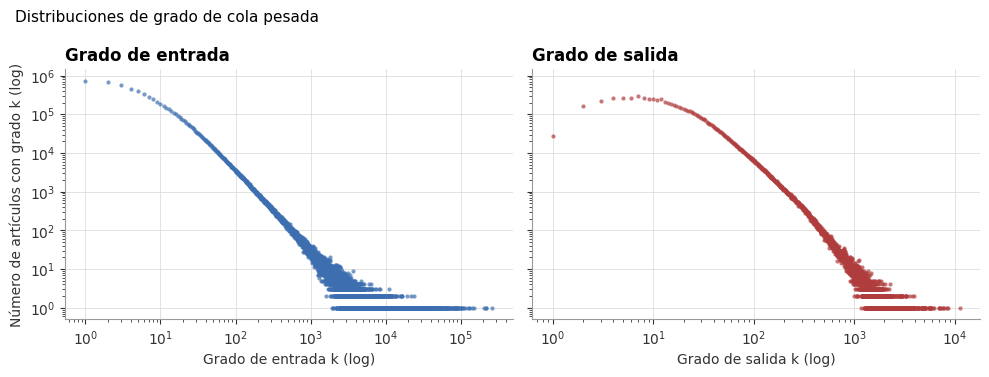

In [30]:
dist_ent = nodos.groupBy("grado_entrada").count().toPandas()
dist_sal = nodos.groupBy("grado_salida").count().toPandas()

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, d, col, color, nombre in ((axs[0], dist_ent, "grado_entrada", AZUL, "entrada"),
                                  (axs[1], dist_sal, "grado_salida", ROJO, "salida")):
    d = d[d[col] > 0]
    ax.scatter(d[col], d["count"], s=9, color=color, alpha=0.7, linewidths=0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"Grado de {nombre} k (log)")
    ax.set_title(f"Grado de {nombre}", loc="left")
axs[0].set_ylabel("Número de artículos con grado k (log)")
fig.suptitle("Distribuciones de grado de cola pesada", x=0.02, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

**Observaciones.** Casi todos los artículos reciben pocos enlaces, y unos cuantos reciben muchísimos. El máximo de entrada es de 264,884 (*Association football*), y el de salida, de 11,197 (*List of birds by common name*). La diferencia tiene sentido: escribir miles de enlaces cuesta trabajo, recibirlos no. El 6.31 % de los artículos no recibe ningún enlace.

In [32]:
print("Artículos con más enlaces de entrada (autoridades por grado):")
nodos.orderBy(F.desc("grado_entrada")).select("title", "grado_entrada", "grado_salida").show(20, truncate=60)

Artículos con más enlaces de entrada (autoridades por grado):


+--------------------+-------------+------------+
|               title|grado_entrada|grado_salida|
+--------------------+-------------+------------+
|Association football|       264884|         332|
|        World War II|       221373|         956|
|       United States|       218778|        1602|
|  The New York Times|       203664|         611|
|       New York City|       149469|        1321|
|              France|       141780|        1194|
|              London|       130318|         906|
|            AllMusic|       129358|          37|
|         World War I|       118475|         682|
|        The Guardian|       112749|         637|
|             Germany|       107263|         943|
|               India|       104323|        1231|
|      United Kingdom|       101510|        1407|
|          U.S. state|       101209|         280|
|             Village|        99569|         381|
|     Catholic Church|        93981|         759|
|             YouTube|        93780|         467|


In [33]:
print("Artículos con más enlaces de salida (listas y desambiguaciones suelen dominar):")
nodos.orderBy(F.desc("grado_salida")).select("title", "grado_salida", "grado_entrada", "is_disambig").show(15, truncate=60)

Artículos con más enlaces de salida (listas y desambiguaciones suelen dominar):


+------------------------------------------------+------------+-------------+-----------+
|                                           title|grado_salida|grado_entrada|is_disambig|
+------------------------------------------------+------------+-------------+-----------+
|                    List of birds by common name|       11197|            3|      false|
|                    List of people from Illinois|        8664|            9|      false|
|                     List of least concern birds|        8343|            8|      false|
|    Alphabetical list of municipalities of Italy|        7952|            2|      false|
|            List of people with given name Peter|        7669|            3|      false|
|               List of places named after people|        7654|           46|      false|
|List of association football stadiums by country|        7363|           80|      false|
|                        List of stock characters|        7140|           54|      false|
|        I

Un ejemplo de los enlaces de un artículo:

In [34]:
# Ejemplo: vecinos de salida y de entrada de un artículo
pid = (nodos.filter(F.col("title") == "PageRank").first()
       or nodos.orderBy(F.desc("grado_entrada")).first())
t = nodos.select(F.col("id").alias("v"), F.col("title").alias("t"))
print(f"{pid.title}: id={pid.id}, idx={pid.idx}, salida={pid.grado_salida}, entrada={pid.grado_entrada}")
print("Algunos artículos a los que enlaza:",
      [x.t for x in aristas.filter(F.col("src") == pid.id).join(t, F.col("dst") == F.col("v")).limit(12).collect()])
print("Algunos artículos que lo enlazan  :",
      [x.t for x in aristas.filter(F.col("dst") == pid.id).join(t, F.col("src") == F.col("v")).limit(12).collect()])

PageRank: id=26334893, idx=2955577, salida=126, entrada=201


Algunos artículos a los que enlaza: ['SALSA algorithm', 'Matt Cutts', 'Python (programming language)', 'Héctor García-Molina', 'Google matrix', 'Expected value', 'Eugene Garfield', 'Teoma', 'Jon Kleinberg', 'HITS algorithm', 'SimRank', 'Link relation']


Algunos artículos que lo enlazan  : ['Paywall', 'SALSA algorithm', 'Matt Cutts', 'Wassily Leontief', 'NetworkX', 'Sports rating system', 'Stanford Digital Library Project', 'Outline of algorithms', 'Amy Langville', 'Chris Barton (businessman)', 'Google matrix', 'MozDex']


In [35]:
pd.Series({sub: tam_dir(GRAFO / sub) for sub in ("nodos", "aristas", "categorias_nodo", "jerarquia_categorias")},
          name="GB en disco").to_frame()

,GB en disco
nodos,0.22
aristas,2.30
categorias_nodo,0.71
jerarquia_categorias,0.12


### 7.2 Qué se quedó del archivo

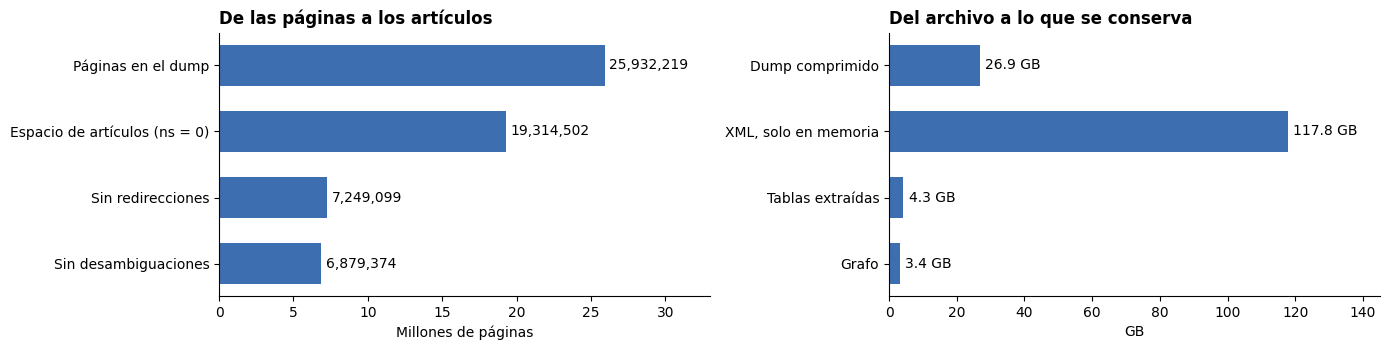

{'enlaces extraídos': 254346209, 'pertenencias a categorías': 47705914}
{'Dump comprimido': 26.92, 'XML, solo en memoria': 117.84, 'Tablas extraídas': 4.25, 'Grafo': 3.36}


In [1]:
# Gráfica 2. Qué se quedó del dump: páginas y tamaño en cada etapa
import glob as _glob
import pyarrow.parquet as pq

DATOS = Path("..") / "data"
por_rango = [json.load(open(ruta, encoding="utf-8")) for ruta in _glob.glob(str(DATOS / "stats" / "*.json"))]
paginas_t = pq.read_table(DATOS / "paginas", columns=["ns", "is_redirect"]).to_pandas()
nodos_t = pq.read_table(DATOS / "grafo" / "nodos", columns=["is_disambig"]).to_pandas()
pasos = {"Páginas en el dump": len(paginas_t), "Espacio de artículos (ns = 0)": (paginas_t["ns"] == 0).sum(),
         "Sin redirecciones": ((paginas_t["ns"] == 0) & ~paginas_t["is_redirect"]).sum(), "Sin desambiguaciones": (~nodos_t["is_disambig"]).sum()}
peso = lambda carpeta: sum(f.stat().st_size for f in (DATOS / carpeta).rglob("*") if f.is_file()) / 1e9
tamanos = {"Dump comprimido": (DATOS / "enwiki-latest-pages-articles-multistream.xml.bz2").stat().st_size / 1e9,
           "XML, solo en memoria": sum(r["bytes_xml"] for r in por_rango) / 1e9,
           "Tablas extraídas": peso("paginas") + peso("enlaces") + peso("categorias"),
           "Grafo": sum(peso(f"grafo/{x}") for x in ("nodos", "aristas", "categorias_nodo", "jerarquia_categorias"))}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.6))
ax1.barh(list(pasos)[::-1], [v / 1e6 for v in list(pasos.values())[::-1]], color="#3D6FB0", height=0.62)
for y, v in enumerate(list(pasos.values())[::-1]):
    ax1.text(v / 1e6 + 0.3, y, f"{v:,}", va="center")
ax1.set_xlim(0, 33)
ax1.set_xlabel("Millones de páginas")
ax1.set_title("De las páginas a los artículos", loc="left", fontweight="bold")
ax2.barh(list(tamanos)[::-1], list(tamanos.values())[::-1], color="#3D6FB0", height=0.62)
for y, v in enumerate(list(tamanos.values())[::-1]):
    ax2.text(v + 1.5, y, f"{v:,.1f} GB", va="center")
ax2.set_xlim(0, 145)
ax2.set_xlabel("GB")
ax2.set_title("Del archivo a lo que se conserva", loc="left", fontweight="bold")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print({"enlaces extraídos": sum(r["enlaces"] for r in por_rango), "pertenencias a categorías": sum(r["categorias"] for r in por_rango)})
print({c: round(v, 2) for c, v in tamanos.items()})

**Observaciones.** Quedan 6.88 millones de artículos de 25.9 millones de páginas: la mayor reducción viene de las redirecciones. En tamaño, pasamos de 117.8 GB de XML, que solo estuvieron en memoria, a 4.25 GB de tablas y 3.36 GB de grafo. También se extrajeron 254,346,209 enlaces a títulos y 47,705,914 pertenencias a categorías.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · CIERRE</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Conclusiones y limitaciones</span></div>

- El archivo trae 25.9 millones de páginas, pero solo 7.25 millones son artículos. El 62.5 % de las páginas del espacio de artículos son redirecciones.
- El índice permitió leer todo el archivo en paralelo en unos 26 minutos sin descomprimirlo a disco, y las páginas extraídas coinciden exactamente con el índice.
- El resultado es un grafo dirigido de 7,249,099 nodos y 236,242,098 aristas, con 32.6 enlaces por artículo en promedio.

**Limitaciones.**

- Los enlaces y las categorías que agregan las plantillas no se cuentan, porque el texto no se expande.
- Las redirecciones se resuelven con un solo salto. Quedan pocas sin resolver porque los bots las corrigen.
- La marca de desambiguación todavía tiene casos aislados equivocados, como las páginas con `{{Split and dab}}`.
- Es una sola versión del archivo y un solo idioma. Otra descarga dará cifras parecidas, pero no idénticas.

In [37]:
spark.stop()